# Text-to-SQL Generation with a Fine-Tuned Transformer (CodeT5-small)

**Project 5: Generative AI Applications**  
**Author:** Ewald Geschwinde

This notebook implements a **transformer-based sequence-to-sequence generator** that turns a natural-language question about a database table into an executable **SQL query**, given the table schema as a `CREATE TABLE` statement.

| Item | Choice |
|---|---|
| Generative approach | Transformer (encoder–decoder), conditional text generation |
| Base model | `Salesforce/codet5-small` (60.5M parameters), fine-tuned end-to-end |
| Dataset | `b-mc2/sql-create-context` (78,577 question / SQL / schema triples from WikiSQL and Spider) |
| Frameworks | PyTorch + Hugging Face Transformers / Datasets |
| Output | A single SQL `SELECT` statement (text) |

## Task 1: Generative Task and Approach

### Goal
Given **(a)** a question written in English, for example *"How many heads of the departments are older than 56?"*, and **(b)** a database schema such as `CREATE TABLE head (age INTEGER)`, the system **generates** the SQL query that answers it: `SELECT COUNT(*) FROM head WHERE age > 56`.

This is open-ended generation: the model writes the query token by token over a ~32k-token vocabulary. It has to copy the right identifiers from the schema, copy literal values from the question, and arrange them with valid SQL syntax. It does not pick from a fixed set of answers.

### Why a transformer (and not a GAN or VAE)
SQL is a discrete token sequence with long-range structure: a column named in `SELECT` must exist in the `CREATE TABLE` clause dozens of tokens earlier. Encoder–decoder transformers handle this well through self-attention and cross-attention (Vaswani et al., 2017). GANs struggle with discrete text because gradients cannot flow through sampled tokens, and VAEs for text tend to collapse their posterior. Both are mainly image-generation tools in this course.

### Why CodeT5-small
* CodeT5 is a T5-style encoder–decoder pretrained on source code with *identifier-aware* objectives (Wang et al., 2021). Copying column and table names correctly is the core skill text-to-SQL needs.
* Its byte-level BPE tokenizer represents every SQL symbol. The original T5 SentencePiece vocabulary cannot encode `<` and maps it to `<unk>`, which would make `WHERE x < 5` impossible to generate.
* At 60M parameters it fine-tunes on a laptop GPU (Apple MPS) in about 30–40 minutes.

### Data source and provenance
* **Dataset:** [`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context) on the Hugging Face Hub (license CC BY 4.0), downloaded with `datasets.load_dataset`. A copy is saved to `data/sql_create_context.csv` for reproducibility.
* **Origin:** The questions and SQL queries come from two human-annotated academic benchmarks:
  * **WikiSQL** (Zhong et al., 2017): questions written and paraphrased by Amazon Mechanical Turk crowdworkers over Wikipedia tables.
  * **Spider** (Yu et al., 2018): complex cross-domain queries written by 11 Yale students.
* **What the curator added:** the `context` column (a `CREATE TABLE` statement). The curator derived it **programmatically** by parsing each gold query for the tables and columns it uses, then inferring a coarse type (`INTEGER` or `VARCHAR`). Nothing in the dataset is AI-generated: the questions and SQL are human-written, and the schema is a deterministic transformation.
* **Use in this project:** `question` and `context` are concatenated into the encoder input, and `answer` (the gold SQL) is the decoder target.

## Setup

In [1]:
import os, re, json, math, random, sqlite3, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
DATA_PATH = "data/sql_create_context.csv"
MODEL_DIR = "models/codet5-small-sql"
OUT_DIR = "outputs"
os.makedirs("data", exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_colwidth", 140)
def free_gpu_cache():
    if DEVICE == "mps":
        torch.mps.empty_cache()

print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.14.1


## Task 2: Load and Inspect the Data

In [2]:
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH, keep_default_na=False)
else:
    df = load_dataset("b-mc2/sql-create-context", split="train").to_pandas()
    df = df[["question", "context", "answer"]]
    df.to_csv(DATA_PATH, index=False)

print("shape:", df.shape)
print("columns:", list(df.columns))
print("dtypes:\n", df.dtypes)
print("\nempty strings per column:\n", (df == "").sum())
print("\nexact duplicate rows:", df.duplicated().sum())

shape: (78577, 3)
columns: ['question', 'context', 'answer']
dtypes:
 question    str
context     str
answer      str
dtype: object

empty strings per column:
 question    0
context     0
answer      0
dtype: int64

exact duplicate rows: 0


### Representative samples

In [3]:
df.sample(8, random_state=1)

,question,context,answer
8841,Who is riding the Ducati 999 RS in Round 7?,"CREATE TABLE table_name_31 (rider VARCHAR, rounds VARCHAR, motorcycle VARCHAR)","SELECT rider FROM table_name_31 WHERE rounds = ""7"" AND motorcycle = ""ducati 999 rs"""
54086,Which Run 3 has a Run 1 of 2:20.10?,"CREATE TABLE table_name_13 (run_3 VARCHAR, run_1 VARCHAR)","SELECT run_3 FROM table_name_13 WHERE run_1 = ""2:20.10"""
17325,What capacity opened lessed than 1937 and is located in the region of champagne-ardenne?,"CREATE TABLE table_name_95 (capacity VARCHAR, opened VARCHAR, region VARCHAR)","SELECT capacity FROM table_name_95 WHERE opened < 1937 AND region = ""champagne-ardenne"""
33790,"Writer Max Ehrlich, what is the minimum series number?","CREATE TABLE table_19852975_4 (series__number INTEGER, writer_s_ VARCHAR)","SELECT MIN(series__number) FROM table_19852975_4 WHERE writer_s_ = ""Max Ehrlich"""
15162,Which IATA's ICAO is rjss?,"CREATE TABLE table_name_17 (iata VARCHAR, icao VARCHAR)","SELECT iata FROM table_name_17 WHERE icao = ""rjss"""
67327,What nation has more than 1 bronze and less than 3 silver?,"CREATE TABLE table_name_45 (nation VARCHAR, bronze VARCHAR, silver VARCHAR)",SELECT nation FROM table_name_45 WHERE bronze > 1 AND silver < 3
62074,What's the First Day Cover Cancellation with Denomination of $0.50 and Date of Issue as 13 June 2005?,"CREATE TABLE table_name_68 (first_day_cover_cancellation VARCHAR, denomination VARCHAR, date_of_issue VARCHAR)","SELECT first_day_cover_cancellation FROM table_name_68 WHERE denomination = ""$0.50"" AND date_of_issue = ""13 june 2005"""
11456,"What is the smallest Weight, when Spike is less than 330, when Block is 315, and when Height is greater than 187?","CREATE TABLE table_name_78 (weight INTEGER, height VARCHAR, spike VARCHAR, block VARCHAR)",SELECT MIN(weight) FROM table_name_78 WHERE spike < 330 AND block = 315 AND height > 187


In [4]:
# A few full examples, including a multi-table (JOIN) Spider example
for i in [0, 5000, 70000]:
    r = df.iloc[i]
    print(f"QUESTION: {r.question}\nCONTEXT : {r.context}\nSQL     : {r.answer}\n")
joined = df[df.answer.str.contains(" JOIN ")].iloc[3]
print(f"QUESTION: {joined.question}\nCONTEXT : {joined.context}\nSQL     : {joined.answer}")

QUESTION: How many heads of the departments are older than 56 ?
CONTEXT : CREATE TABLE head (age INTEGER)
SQL     : SELECT COUNT(*) FROM head WHERE age > 56

QUESTION: What is the name of the institution with the mascot of blue devils?
CONTEXT : CREATE TABLE table_12434380_1 (institution VARCHAR, mascot VARCHAR)
SQL     : SELECT institution FROM table_12434380_1 WHERE mascot = "Blue Devils"

QUESTION: What Title has the Label of Columbia and Standard number of CODC-8760?
CONTEXT : CREATE TABLE table_name_27 (title VARCHAR, label VARCHAR, standard_number VARCHAR)
SQL     : SELECT title FROM table_name_27 WHERE label = "columbia" AND standard_number = "codc-8760"

QUESTION: List the states where both the secretary of 'Treasury' department and the secretary of 'Homeland Security' were born.
CONTEXT : CREATE TABLE management (department_id VARCHAR, head_id VARCHAR); CREATE TABLE head (born_state VARCHAR, head_id VARCHAR); CREATE TABLE department (department_id VARCHAR, name VARCHAR)
SQL   

### Structure: where do examples come from, and how complex are they?
WikiSQL tables are anonymised as `table_<id>` or `table_name_<n>`. Spider uses real table names (e.g. `head`, `department`), so the table name tells us which source each example came from.

In [5]:
df["source"] = np.where(df.context.str.match(r"CREATE TABLE table_"), "WikiSQL", "Spider")

def sql_features(q):
    u = q.upper()
    return {
        "JOIN": " JOIN " in u,
        "GROUP BY": "GROUP BY" in u,
        "ORDER BY": "ORDER BY" in u,
        "nested SELECT": u.count("SELECT") > 1,
        "aggregate": bool(re.search(r"\b(COUNT|SUM|AVG|MIN|MAX)\s*\(", u)),
        "WHERE": " WHERE " in u,
    }

feat = pd.DataFrame([sql_features(q) for q in df.answer])
df = pd.concat([df, feat], axis=1)
df["n_tables"] = df.context.str.count("CREATE TABLE")

print(df.source.value_counts(), "\n")
print("share of queries containing each construct (%):")
print((feat.groupby(df.source).mean() * 100).round(1).T)
print("\ntables per schema:\n", df.n_tables.value_counts().sort_index())

source
WikiSQL    74037
Spider      4540
Name: count, dtype: int64 

share of queries containing each construct (%):
source         Spider  WikiSQL
JOIN             39.4      0.0
GROUP BY         25.6      0.0
ORDER BY         23.4      0.0
nested SELECT    14.6      0.0
aggregate        47.0     28.0
WHERE            49.2     99.2

tables per schema:
 n_tables
1    76576
2     1457
3      473
4       64
5        7
Name: count, dtype: int64


### Sequence lengths (characters and tokens)

       src_tokens  tgt_tokens
count     78577.0     78577.0
mean         43.3        27.3
std          11.2         9.8
min          18.0         6.0
50%          41.0        25.0
95%          64.0        43.0
99%          80.0        63.0
99.9%       106.0       105.4
max         264.0       249.0

inputs > 256 tokens: 2 | targets > 128 tokens: 34


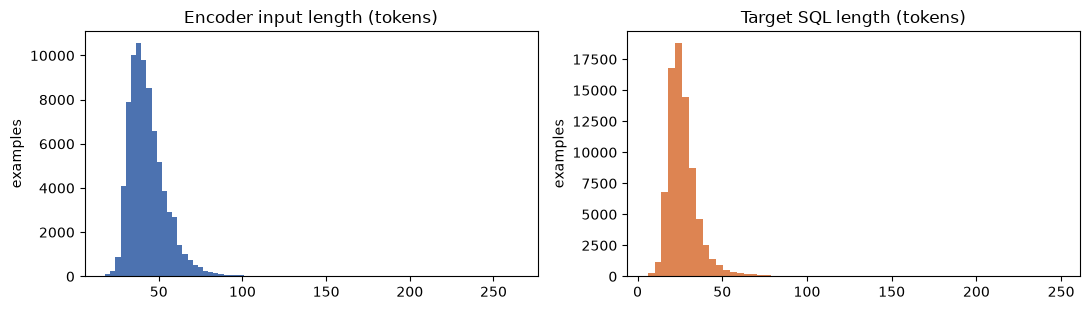

In [6]:
MODEL_NAME = "Salesforce/codet5-small"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_source(question, context):
    # Input format fed to the encoder
    return f"question: {question} schema: {context}"

src_len = [len(x) for x in tokenizer([make_source(q, c) for q, c in zip(df.question, df.context)]).input_ids]
tgt_len = [len(x) for x in tokenizer(list(df.answer)).input_ids]
df["src_tokens"], df["tgt_tokens"] = src_len, tgt_len
print(df[["src_tokens", "tgt_tokens"]].describe(percentiles=[.5, .95, .99, .999]).round(1))
print(f"\ninputs > 256 tokens: {(df.src_tokens > 256).sum()} | targets > 128 tokens: {(df.tgt_tokens > 128).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(df.src_tokens, bins=80, color="#4C72B0"); axes[0].set_title("Encoder input length (tokens)")
axes[1].hist(df.tgt_tokens, bins=60, color="#DD8452"); axes[1].set_title("Target SQL length (tokens)")
for a in axes: a.set_ylabel("examples")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/length_hist.png", dpi=150); plt.show()

In [7]:
# Does the tokenizer round-trip every SQL string losslessly? (T5's tokenizer would fail on '<')
sample = df.answer.sample(5000, random_state=0)
bad = [s for s in sample if tokenizer.decode(tokenizer(s).input_ids, skip_special_tokens=True) != s]
print(f"round-trip failures: {len(bad)} / {len(sample)}")
print(bad[:3])

round-trip failures: 0 / 5000
[]


### Preprocessing considerations
* **Lengths:** sequences are short (median 41 input and 25 target tokens). Only a handful of examples exceed 256 input or 128 target tokens, so we truncate at `MAX_SRC=256` and `MAX_TGT=128` and pad dynamically per batch to avoid wasting compute on padding.
* **Duplicates:** exact duplicate rows are dropped so they cannot land in both train and test.
* **Leakage across splits:** many WikiSQL questions share one table. A random row split would let the model see the *same schema* during training and testing, which inflates the scores. We therefore split **by schema string (`context`)**, so every test schema is unseen during training.
* **Class imbalance:** roughly 90% of examples are single-table WikiSQL queries, and only a minority are multi-table Spider queries with `JOIN` or `GROUP BY`. We expect much weaker performance on the complex Spider queries and report results per source.
* **Literal casing:** WikiSQL gold queries often lowercase the values (`label = "columbia"`) even when the question capitalises them. The model must learn this dataset convention, and exact-match scoring is sensitive to it.
* **Schema format:** `context` lists only the columns used by the gold query. This makes the task easier than real-world text-to-SQL, where the schema also contains distractor columns. This is a known limitation of the dataset.

In [8]:
df = df.drop_duplicates(subset=["question", "context", "answer"]).reset_index(drop=True)

# Group split by schema: every test/validation schema is unseen during training.
contexts = df.context.unique().tolist()   # order of first appearance -> deterministic
rng = np.random.default_rng(SEED)
rng.shuffle(contexts)
n = len(contexts)
val_ctx = set(contexts[: int(0.05 * n)])
test_ctx = set(contexts[int(0.05 * n): int(0.10 * n)])
split = np.where(df.context.isin(test_ctx), "test", np.where(df.context.isin(val_ctx), "val", "train"))
train_df, val_df, test_df = (df[split == s].reset_index(drop=True) for s in ["train", "val", "test"])

print({k: len(v) for k, v in [("train", train_df), ("val", val_df), ("test", test_df)]})
print("schema overlap train/test:", len(set(train_df.context) & set(test_df.context)))
print(test_df.source.value_counts())

{'train': 70715, 'val': 3921, 'test': 3941}
schema overlap train/test: 0
source
WikiSQL    3699
Spider      242
Name: count, dtype: int64


## Task 3: Model Architecture and Training

### Architecture
CodeT5-small has the T5 encoder–decoder architecture (Raffel et al., 2020):

* **Embedding:** a 32,100-token byte-level BPE vocabulary mapped to a 512-dimensional embedding that the encoder, decoder and output projection share.
* **Encoder:** 6 transformer blocks. Each block has multi-head self-attention (8 heads, 64 dimensions per head) followed by a ReLU feed-forward network (512 → 2048 → 512), with pre-layer-norm (RMSNorm) and residual connections. Position is encoded through learned **relative position biases** rather than absolute embeddings, so the model generalises to schemas of different lengths.
* **Decoder:** 6 blocks with *causal* masked self-attention, **cross-attention** over the encoder output, and the same feed-forward layers. Cross-attention is how the decoder "looks up" column names and literal values in the question and schema while writing the query.
* **LM head:** a linear projection to the vocabulary, followed by softmax, gives \(p(y_t \mid y_{<t}, x)\).

### Key design choices
| Choice | Rationale |
|---|---|
| Fine-tune a pretrained code model, not train from scratch | 78k examples are far too few to learn English and SQL syntax from scratch. Transfer learning from code pretraining is the standard approach (Raffel et al., 2020; Wang et al., 2021). |
| Encoder–decoder rather than decoder-only | The input (question and schema) and the output (SQL) are distinct sequences. Bidirectional encoding of the full schema helps copying. |
| Input format `question: … schema: …` | Simple textual prompt. The keywords act as segment markers. |
| Loss: token-level cross-entropy with teacher forcing | The maximum-likelihood objective for autoregressive generation. Padding positions are masked with `-100`. |
| AdamW, lr 3e-4, weight decay 0.01, linear warm-up and decay, grad-clip 1.0 | AdamW decouples weight decay from the adaptive update (Loshchilov & Hutter, 2019). A learning rate around 3e-4 is a common, stable setting for fine-tuning small T5 models. Warm-up and clipping prevent early instability. |
| 3 epochs, batch size 32, best checkpoint chosen by validation loss | Enough passes to converge on this data size, with early-stopping-style checkpoint selection to avoid overfitting. |
| Beam search (4 beams) at evaluation time | Searching over several high-probability queries improves exactness compared with greedy decoding. |

In [9]:
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE)
print(model.config.model_type, "| d_model", model.config.d_model, "| layers", model.config.num_layers,
      "+", model.config.num_decoder_layers, "| heads", model.config.num_heads, "| d_ff", model.config.d_ff,
      "| vocab", model.config.vocab_size)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M\n")
print(model)

t5 | d_model 512 | layers 6 + 6 | heads 8 | d_ff 2048 | vocab 32100
trainable parameters: 60.5M

T5ForConditionalGeneration(
  (shared): Embedding(32100, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32100, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
       

### Baseline: the pretrained model *before* fine-tuning
CodeT5 was pretrained with span denoising on code, not on text-to-SQL. Its zero-shot outputs show what fine-tuning has to teach it.

In [10]:
@torch.no_grad()
def generate_sql(model, questions, contexts, batch_size=64, num_beams=4, **gen_kwargs):
    model.eval()
    outs = []
    for i in range(0, len(questions), batch_size):
        srcs = [make_source(q, c) for q, c in zip(questions[i:i+batch_size], contexts[i:i+batch_size])]
        enc = tokenizer(srcs, max_length=256, truncation=True, padding=True, return_tensors="pt").to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=128, num_beams=num_beams, **gen_kwargs)
        outs.extend(tokenizer.batch_decode(gen, skip_special_tokens=True))
    free_gpu_cache()
    return [o.strip() for o in outs]

demo = test_df.sample(4, random_state=3)
for q, c, g, p in zip(demo.question, demo.context, demo.answer,
                      generate_sql(model, list(demo.question), list(demo.context))):
    print(f"Q: {q}\n   gold      : {g}\n   zero-shot : {p!r}\n")

Q: What is listed under Played that has a Club of Morriston RFC?
   gold      : SELECT played FROM table_name_35 WHERE club = "morriston rfc"
   zero-shot : 'def'

Q: When did acharya shree koshalendraprasadji maharaj become acharya?
   gold      : SELECT became_acharya_on FROM table_name_12 WHERE name_of_acharya = "acharya shree koshalendraprasadji maharaj"
   zero-shot : 'name_of_acharya'

Q: Name the result for  augustine h. shepperd (j) 100%
   gold      : SELECT result FROM table_2668243_18 WHERE candidates = "Augustine H. Shepperd (J) 100%"
   zero-shot : 'def'

Q: Which friendly competition took place on 19 April 1979?
   gold      : SELECT score FROM table_name_37 WHERE competition = "friendly" AND date = "19 april 1979"
   zero-shot : 'def'



### Tokenisation and data loaders

In [11]:
MAX_SRC, MAX_TGT, BATCH_SIZE = 256, 128, 32

class Seq2SeqData(torch.utils.data.Dataset):
    def __init__(self, frame):
        self.src = tokenizer([make_source(q, c) for q, c in zip(frame.question, frame.context)],
                             max_length=MAX_SRC, truncation=True).input_ids
        self.tgt = tokenizer(list(frame.answer), max_length=MAX_TGT, truncation=True).input_ids
    def __len__(self): return len(self.src)
    def __getitem__(self, i): return self.src[i], self.tgt[i]

def collate(batch, multiple=16):
    # Pad to a multiple of 16 tokens: limits the number of distinct tensor shapes, which keeps
    # the MPS (Apple GPU) allocator cache from growing without bound.
    src, tgt = zip(*batch)
    pad_len = lambda seqs: math.ceil(max(map(len, seqs)) / multiple) * multiple
    pad = lambda seqs, v: torch.tensor([s + [v] * (pad_len(seqs) - len(s)) for s in seqs])
    input_ids = pad(src, tokenizer.pad_token_id)
    return {"input_ids": input_ids,
            "attention_mask": (input_ids != tokenizer.pad_token_id).long(),
            "labels": pad(tgt, -100)}          # -100 = ignored by the loss

train_ds, val_ds = Seq2SeqData(train_df), Seq2SeqData(val_df)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, collate_fn=collate)
b = next(iter(train_dl))
print({k: tuple(v.shape) for k, v in b.items()}, "| train batches/epoch:", len(train_dl))

{'input_ids': (32, 96), 'attention_mask': (32, 96), 'labels': (32, 64)} | train batches/epoch: 2210


### Training loop
The loop is written explicitly in PyTorch: forward pass with teacher forcing, cross-entropy over the vocabulary, backpropagation, gradient clipping, an AdamW step and a scheduler step. Validation loss is measured every 500 steps, and validation exact-match on 500 held-out questions after each epoch.

In [12]:
EPOCHS, LR, WEIGHT_DECAY, WARMUP_FRAC, EVAL_EVERY = 3, 3e-4, 0.01, 0.05, 500

LOG_PATH = f"{OUT_DIR}/train_log.txt"
open(LOG_PATH, "w").close()
def log(msg):
    print(msg, flush=True)
    with open(LOG_PATH, "a") as f:
        f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

def seq2seq_loss(model, batch):
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    # Passing labels makes the model build decoder inputs by shifting labels right (teacher forcing)
    logits = model(**batch).logits                                  # (B, T, V)
    return F.cross_entropy(logits.view(-1, logits.size(-1)), batch["labels"].view(-1), ignore_index=-100)

@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for batch in loader:
        tot += seq2seq_loss(model, batch).item() * len(batch["input_ids"]); n += len(batch["input_ids"])
    free_gpu_cache()
    model.train()
    return tot / n

def norm_sql(s):
    s = s.strip().rstrip(";").replace('"', "'").lower()
    s = re.sub(r"\s*([(),=<>])\s*", r" \1 ", s)
    return re.sub(r"\s+", " ", s).strip()

val_probe = val_df.sample(500, random_state=0)
def val_exact_match(model):
    preds = generate_sql(model, list(val_probe.question), list(val_probe.context), num_beams=1)
    model.train()
    return np.mean([norm_sql(p) == norm_sql(g) for p, g in zip(preds, val_probe.answer)])

no_decay = ["bias", "layer_norm.weight"]
params = [
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(params, lr=LR)
total_steps = EPOCHS * len(train_dl)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRAC * total_steps), total_steps)

history = {"step": [], "train_loss": [], "lr": [], "val_step": [], "val_loss": [], "epoch_val_em": []}
best_val, step, running, t0 = float("inf"), 0, [], time.time()
log(f"steps/epoch {len(train_dl)} | total {total_steps}")
history["val_step"].append(0); history["val_loss"].append(evaluate_loss(model, val_dl))
log(f"step 0 | val loss {history['val_loss'][-1]:.3f}")

model.train()
for epoch in range(1, EPOCHS + 1):
    for batch in train_dl:
        loss = seq2seq_loss(model, batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
        step += 1; running.append(loss.item())

        if step % 100 == 0:
            free_gpu_cache()
        if step % 50 == 0:
            history["step"].append(step); history["train_loss"].append(np.mean(running))
            history["lr"].append(scheduler.get_last_lr()[0]); running = []
        if step % EVAL_EVERY == 0 or step == total_steps:
            vl = evaluate_loss(model, val_dl)
            history["val_step"].append(step); history["val_loss"].append(vl)
            tag = ""
            if vl < best_val:
                best_val = vl; model.save_pretrained(MODEL_DIR); tokenizer.save_pretrained(MODEL_DIR); tag = "  <- best, saved"
            recent = history["train_loss"][-1] if history["train_loss"] else loss.item()
            log(f"epoch {epoch} step {step:5d} | train {recent:.4f} | val {vl:.4f} "
                  f"| {(time.time()-t0)/60:.1f} min{tag}")
    em = val_exact_match(model)
    history["epoch_val_em"].append(em)
    free_gpu_cache()
    log(f"=== end of epoch {epoch}: validation exact match (greedy, n=500) = {em:.3f}")

json.dump(history, open(f"{OUT_DIR}/training_history.json", "w"))
log(f"training time: {(time.time()-t0)/60:.1f} min, best val loss {best_val:.4f}")

steps/epoch 2210 | total 6630


step 0 | val loss 4.682


epoch 1 step   500 | train 0.1731 | val 0.1222 | 5.7 min  <- best, saved


epoch 1 step  1000 | train 0.1223 | val 0.0928 | 11.1 min  <- best, saved


epoch 1 step  1500 | train 0.1032 | val 0.0761 | 16.6 min  <- best, saved


...

epoch 3 step  6000 | train 0.0438 | val 0.0469 | 65.3 min  <- best, saved


epoch 3 step  6500 | train 0.0393 | val 0.0460 | 70.7 min  <- best, saved


epoch 3 step  6630 | train 0.0373 | val 0.0461 | 72.2 min


=== end of epoch 3: validation exact match (greedy, n=500) = 0.830


training time: 72.4 min, best val loss 0.0460


### Training diagnostics

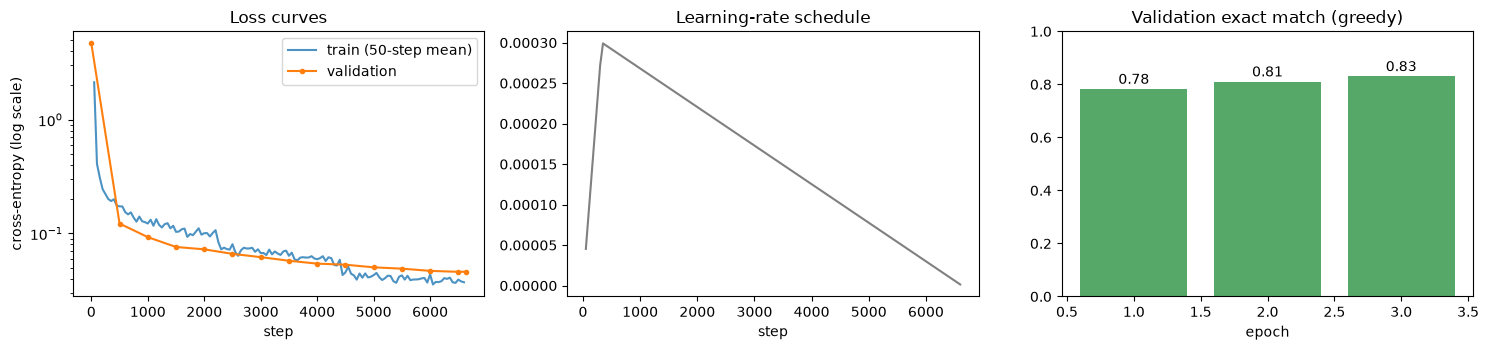

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(history["step"], history["train_loss"], label="train (50-step mean)", alpha=.8)
axes[0].plot(history["val_step"], history["val_loss"], "o-", label="validation", ms=3)
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("cross-entropy (log scale)")
axes[0].set_title("Loss curves"); axes[0].legend()
axes[1].plot(history["step"], history["lr"], color="gray"); axes[1].set_title("Learning-rate schedule"); axes[1].set_xlabel("step")
axes[2].bar(range(1, len(history["epoch_val_em"]) + 1), history["epoch_val_em"], color="#55A868")
axes[2].set_ylim(0, 1); axes[2].set_xlabel("epoch"); axes[2].set_title("Validation exact match (greedy)")
for i, v in enumerate(history["epoch_val_em"]): axes[2].text(i + 1, v + .02, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

## Task 4: Generate and Evaluate Outputs
We reload the **best checkpoint** (lowest validation loss) and generate SQL for the **held-out test set** (all schemas unseen during training) using beam search.

In [14]:
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR).to(DEVICE)
t0 = time.time()
test_df["pred"] = generate_sql(model, list(test_df.question), list(test_df.context), num_beams=4)
print(f"generated {len(test_df)} queries in {time.time()-t0:.0f}s")

generated 3941 queries in 283s


### Multiple generated examples

In [15]:
for _, r in test_df.sample(10, random_state=7).iterrows():
    mark = "✓" if norm_sql(r.pred) == norm_sql(r.answer) else "✗"
    print(f"[{r.source}] Q: {r.question}\n  schema: {r.context}\n  gold  : {r.answer}\n  {mark} pred: {r.pred}\n")

[WikiSQL] Q: What is the home team score of the Ghantoot Racing and Polo Club Ground?
  schema: CREATE TABLE table_name_25 (home_team VARCHAR, ground VARCHAR)
  gold  : SELECT home_team AS score FROM table_name_25 WHERE ground = "ghantoot racing and polo club"
  ✗ pred: SELECT home_team AS score FROM table_name_25 WHERE ground = "polo club ground"

[WikiSQL] Q: what is the overall record when the club is dallas burn?
  schema: CREATE TABLE table_1246208_5 (overall_record VARCHAR, club VARCHAR)
  gold  : SELECT overall_record FROM table_1246208_5 WHERE club = "Dallas Burn"
  ✓ pred: SELECT overall_record FROM table_1246208_5 WHERE club = "Dallas Burn"

[WikiSQL] Q: What country id Bob Rosburg from?
  schema: CREATE TABLE table_name_95 (country VARCHAR, player VARCHAR)
  gold  : SELECT country FROM table_name_95 WHERE player = "bob rosburg"
  ✓ pred: SELECT country FROM table_name_95 WHERE player = "bob rosburg"

[WikiSQL] Q: Which visitor had a record of 7–5–3?
  schema: CREATE TABLE ta

In [16]:
# Complex (Spider, multi-table) examples
for _, r in test_df[test_df.JOIN].sample(5, random_state=1).iterrows():
    mark = "✓" if norm_sql(r.pred) == norm_sql(r.answer) else "✗"
    print(f"Q: {r.question}\n  schema: {r.context}\n  gold  : {r.answer}\n  {mark} pred: {r.pred}\n")

Q: find the name of driver who is driving the school bus with the longest working history.
  schema: CREATE TABLE school_bus (driver_id VARCHAR); CREATE TABLE driver (name VARCHAR, driver_id VARCHAR)
  gold  : SELECT t1.name FROM driver AS t1 JOIN school_bus AS t2 ON t1.driver_id = t2.driver_id ORDER BY years_working DESC LIMIT 1
  ✗ pred: SELECT T1.name FROM driver AS T1 JOIN school_bus AS T2 ON T1.driver_id = T2.driver_id ORDER BY working_history DESC LIMIT 1

Q: Find the subject ID, name of subject and the corresponding number of courses for each subject, and sort by the course count in ascending order.
  schema: CREATE TABLE Courses (subject_id VARCHAR); CREATE TABLE Subjects (subject_name VARCHAR, subject_id VARCHAR)
  gold  : SELECT T1.subject_id, T2.subject_name, COUNT(*) FROM Courses AS T1 JOIN Subjects AS T2 ON T1.subject_id = T2.subject_id GROUP BY T1.subject_id ORDER BY COUNT(*)
  ✗ pred: SELECT T1.subject_id, T1.subject_name, COUNT(*) FROM Subjects AS T1 JOIN Courses AS T2 

### Quantitative metrics
* **Exact match (EM):** the prediction equals the gold query after normalising case, quote style and whitespace. This is strict, because a semantically equivalent query written differently counts as wrong.
* **Valid SQL:** the prediction runs without error in SQLite against the schema. This checks syntax and that every referenced table and column exists.
* **Execution accuracy (EX):** both queries run on a small **randomly populated** database built from the schema, and their result sets are compared. Each column is filled from the literals in the question and gold query plus random values. This follows the idea of test-suite evaluation (Zhong, Yu & Klein, 2020) in a simplified, single-database form, so EX is an *upper-bound-ish* estimate: two different queries can agree on one small random database by chance.

In [17]:
def parse_schema(context):
    # "CREATE TABLE a (x VARCHAR); CREATE TABLE b (...)" -> {table: {column: type}}.
    # A table can appear several times with different column subsets, so merge them
    # (case-insensitively, like SQLite itself).
    schema = {}
    for table, cols in re.findall(r"CREATE TABLE (\w+) \(([^)]*)\)", context):
        for col in cols.split(","):
            name, typ = col.split()
            schema.setdefault(table.lower(), {}).setdefault(name.lower(), typ)
    return schema

def build_db(context):
    con = sqlite3.connect(":memory:")
    for table, cols in parse_schema(context).items():
        con.execute(f'CREATE TABLE "{table}" ({", ".join(f'"{c}" {t}' for c, t in cols.items())})')
    return con

def run(con, sql):
    con.set_progress_handler(lambda: 1, 2_000_000)   # abort runaway queries
    return con.execute(sql).fetchall()

def is_valid(context, sql):
    try:
        run(build_db(context), sql); return True
    except Exception:
        return False

def populate(con, context, gold, question, seed, n_rows=25):
    rnd = random.Random(seed)
    strs = re.findall(r"['\"]([^'\"]*)['\"]", gold)
    nums = [float(x) if "." in x else int(x) for x in re.findall(r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w.])", gold + " " + question)]
    num_pool = nums + [n + d for n in nums for d in (-1, 1)] + [rnd.randint(0, 100) for _ in range(5)]
    str_pool = strs + [s.upper() for s in strs] + [s.title() for s in strs] + [f"v{rnd.randint(0, 999)}" for _ in range(5)]
    for table, cols in parse_schema(context).items():
        for _ in range(n_rows):
            row = [rnd.choice(num_pool) if (t.upper() == "INTEGER" or rnd.random() < .3) and num_pool
                   else rnd.choice(str_pool) for t in cols.values()]
            con.execute(f"INSERT INTO \"{table}\" VALUES ({','.join('?' * len(row))})", row)

def exec_match(r, seed):
    con = build_db(r.context)
    populate(con, r.context, r.answer, r.question, seed)
    try:
        g = run(con, r.answer)
    except Exception:
        return None                       # gold itself fails -> excluded
    try:
        p = run(con, r.pred)
    except Exception:
        return False
    ordered = "order by" in r.answer.lower()
    canon = lambda rows: [tuple(str(v) for v in row) for row in rows]
    return canon(g) == canon(p) if ordered else Counter(canon(g)) == Counter(canon(p))

test_df["em"] = [norm_sql(p) == norm_sql(g) for p, g in zip(test_df.pred, test_df.answer)]
test_df["valid"] = [is_valid(c, p) for c, p in zip(test_df.context, test_df.pred)]
test_df["ex"] = [exec_match(r, i) for i, r in enumerate(test_df.itertuples())]
ex_ok = test_df.ex.notna()
print(f"test examples: {len(test_df)} (gold executable: {ex_ok.sum()})")
print(f"Exact match       : {test_df.em.mean():.3f}")
print(f"Valid SQL         : {test_df.valid.mean():.3f}")
print(f"Execution accuracy: {test_df.loc[ex_ok, 'ex'].astype(bool).mean():.3f}")

test examples: 3941 (gold executable: 3839)
Exact match       : 0.820
Valid SQL         : 0.962
Execution accuracy: 0.885


,n,exact match,valid SQL,execution acc.
subset,,,,
All,3941,0.820,0.962,0.885
WikiSQL,3699,0.840,0.976,0.901
Spider,242,0.508,0.736,0.633
WHERE,3785,0.827,0.967,0.892
aggregate,1171,0.694,0.921,0.791
ORDER BY,61,0.459,0.689,0.569
GROUP BY,65,0.323,0.708,0.452
JOIN,119,0.160,0.504,0.327
nested SELECT,36,0.417,0.750,0.556


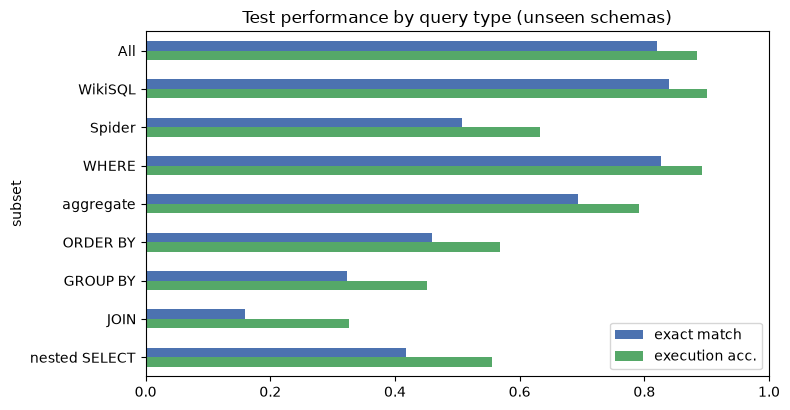

In [18]:
rows = []
for name, mask in [("All", test_df.index == test_df.index), ("WikiSQL", test_df.source == "WikiSQL"),
                   ("Spider", test_df.source == "Spider"), ("WHERE", test_df["WHERE"]),
                   ("aggregate", test_df["aggregate"]), ("ORDER BY", test_df["ORDER BY"]),
                   ("GROUP BY", test_df["GROUP BY"]), ("JOIN", test_df["JOIN"]), ("nested SELECT", test_df["nested SELECT"])]:
    sub = test_df[mask]; e = sub[sub.ex.notna()]
    rows.append({"subset": name, "n": len(sub), "exact match": sub.em.mean(),
                 "valid SQL": sub.valid.mean(), "execution acc.": e.ex.astype(bool).mean()})
metrics = pd.DataFrame(rows).set_index("subset").round(3)
metrics.to_csv(f"{OUT_DIR}/test_metrics.csv")
display(metrics)

ax = metrics[["exact match", "execution acc."]].plot.barh(figsize=(8, 4.2), color=["#4C72B0", "#55A868"])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title("Test performance by query type (unseen schemas)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/metrics_by_type.png", dpi=150); plt.show()

### Failure analysis
We sort the incorrect predictions into coarse error categories with simple heuristics, then look at concrete examples.

In [19]:
def error_type(r):
    if r.em or r.ex is True:
        return "correct"
    if not r.valid:
        return "invalid SQL / unknown column"
    p, g = norm_sql(r.pred), norm_sql(r.answer)
    lit = lambda s: sorted(re.findall(r"'[^']*'|\b\d+(?:\.\d+)?\b", s))
    agg = lambda s: re.findall(r"\b(count|sum|avg|min|max)\s*\(", s)
    sel = lambda s: s.split(" from ")[0]
    if lit(p) != lit(g) and re.sub(r"'[^']*'|\b\d+(?:\.\d+)?\b", "#", p) == re.sub(r"'[^']*'|\b\d+(?:\.\d+)?\b", "#", g):
        return "wrong literal value only"
    if agg(p) != agg(g):
        return "wrong aggregation"
    if sel(p) != sel(g):
        return "wrong SELECT column(s)"
    return "wrong condition / structure"

test_df["error_type"] = [error_type(r) for r in test_df.itertuples()]
err = test_df.error_type.value_counts()
display(pd.DataFrame({"count": err, "share": (err / len(test_df)).round(3)}))

for et in [e for e in err.index if e != "correct"]:
    print(f"\n### {et}")
    for _, r in test_df[test_df.error_type == et].sample(min(3, (test_df.error_type == et).sum()), random_state=0).iterrows():
        print(f"Q: {r.question}\n  gold: {r.answer}\n  pred: {r.pred}")

,count,share
error_type,,
correct,3508,0.890
wrong aggregation,188,0.048
invalid SQL / unknown column,101,0.026
wrong literal value only,84,0.021
wrong condition / structure,32,0.008
wrong SELECT column(s),28,0.007



### wrong aggregation
Q: How many people led in points during the game on October 5?
  gold: SELECT COUNT(high_points) FROM table_27698941_2 WHERE date = "October 5"
  pred: SELECT high_points FROM table_27698941_2 WHERE date = "October 5"
Q: What is the election year when the # of candidates nominated was 262?
  gold: SELECT COUNT(election) FROM table_123462_2 WHERE _number_of_candidates_nominated = 262
  pred: SELECT election FROM table_123462_2 WHERE _number_of_candidates_nominated = 262
Q: How many Bronze medals did the team ranked 1 win?
  gold: SELECT bronze FROM table_name_32 WHERE rank = "1"
  pred: SELECT COUNT(bronze) FROM table_name_32 WHERE rank = 1

### invalid SQL / unknown column
Q: Find the top 3 artists who have the largest number of songs works whose language is Bangla.
  gold: SELECT T1.artist_name FROM artist AS T1 JOIN song AS T2 ON T1.artist_name = T2.artist_name WHERE T2.languages = "bangla" GROUP BY T2.artist_name ORDER BY COUNT(*) DESC LIMIT 3
  pred: SELECT a

In [20]:
test_df[["source", "question", "context", "answer", "pred", "em", "valid", "ex", "error_type"]].to_csv(
    f"{OUT_DIR}/test_predictions.csv", index=False)

### Output variability: beam search vs. sampling
Text-to-SQL normally wants the single most likely query. To examine the *generative distribution* itself, we draw several samples per question with nucleus (top-p) sampling (Holtzman et al., 2020) at two temperatures. Then we measure how many distinct queries appear and how many of them are valid or correct.

In [21]:
torch.manual_seed(0)
probe = test_df[test_df.source == "Spider"].sample(3, random_state=11)
for _, r in probe.iterrows():
    print(f"Q: {r.question}\n  gold: {r.answer}")
    for temp in (0.7, 1.3):
        samples = generate_sql(model, [r.question] * 6, [r.context] * 6, num_beams=1,
                               do_sample=True, top_p=0.95, temperature=temp)
        for s in dict.fromkeys(samples):
            ok = "✓" if norm_sql(s) == norm_sql(r.answer) else ("valid" if is_valid(r.context, s) else "INVALID")
            print(f"    T={temp}: [{ok}] {s}")
    print()

Q: Show the locations that have both performances with more than 2000 attendees and performances with less than 1000 attendees.
  gold: SELECT LOCATION FROM performance WHERE Attendance > 2000 INTERSECT SELECT LOCATION FROM performance WHERE Attendance < 1000


    T=0.7: [✓] SELECT LOCATION FROM performance WHERE Attendance > 2000 INTERSECT SELECT LOCATION FROM performance WHERE Attendance < 1000


    T=1.3: [✓] SELECT LOCATION FROM performance WHERE Attendance > 2000 INTERSECT SELECT LOCATION FROM performance WHERE Attendance < 1000
    T=1.3: [valid] SELECT LOCATION FROM performance WHERE Attendance > 2000 INTERSECT SELECT LOCATION FROM performance GROUP BY LOCATION HAVING AVG(Attendance) < 1000

Q: Find the name of students who have taken the prerequisite course of the course with title International Finance.
  gold: SELECT T1.name FROM student AS T1 JOIN takes AS T2 ON T1.id = T2.id WHERE T2.course_id IN (SELECT T4.prereq_id FROM course AS T3 JOIN prereq AS T4 ON T3.course_id = T4.course_id WHERE T3.title = 'International Finance')


    T=0.7: [INVALID] SELECT T1.name FROM student AS T1 JOIN prereq AS T2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T2.course_id = T3.course_id WHERE T3.title = "International Finance"
    T=0.7: [INVALID] SELECT T2.name FROM prereq AS T1 JOIN student AS T2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T1.course_id = T3.course_id WHERE T3.title = 'International Finance' INTERSECT SELECT T2.name FROM prereq AS T1 JOIN student AS T2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T3.course_id = T2.course_id JOIN takes AS T3 ON T2.course_id = T
    T=0.7: [INVALID] SELECT T3.name FROM prereq AS T1 JOIN takes AS T2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T1.course_id = T3.course_id WHERE T1.title = "International Finance"
    T=0.7: [INVALID] SELECT T3.name FROM prereq AS T1 JOIN takes AS T2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T1.course_id = T3.course_id WHERE T1.title = 'International Finance'
    T=0.7: [INVALID] SELECT DISTINCT t3.name FROM prereq AS t1 JOIN takes AS t2 ON t

    T=1.3: [INVALID] SELECT DISTINCT t1.name FROM student AS t1 JOIN prereq AS t2 ON t1.core_id = t2.prereq_id JOIN course AS t3 ON t2.course_id = t3.course_id WHERE t2.title = "International Finance" INTERSECT SELECT t1.name FROM student AS t1 JOIN prereq AS t2 ON t1.prereq_id = t2.prereq_id JOIN courses AS t3 ON t2.course_id = t3.course_id WHERE t1.id =
    T=1.3: [INVALID] SELECT T1.name FROM student AS T1 JOIN prereq AS T2 ON T1.type_ = T2.id JOIN course AS T3 ON T2.course_id = T3.course_id WHERE T3.title = 'International Finance'
    T=1.3: [valid] SELECT T1.name FROM student AS T1 JOIN prereq AS T2 ON T1.id = T2.prereq_id JOIN course AS T3 ON T2.course_id = T3.course_id WHERE T3.title = "International Finance"
    T=1.3: [INVALID] SELECT T2.name FROM prereq AS T1 JOIN take AS t2 ON T1.prereq_id = T2.id JOIN course AS T3 ON T1.course_id = T3.course_id JOIN course AS T4 ON T4.course_id = T3.id WHERE T4.title = "International Finance"
    T=1.3: [INVALID] SELECT t3.name FROM prereq 

    T=0.7: [INVALID] SELECT T2.Pilot_name, T1.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T3.Pilot_ID = T2.Pilot_ID
    T=0.7: [INVALID] SELECT T2.Pilot_name, T2.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T1.Pilot_ID = T3.Pilot_ID
    T=0.7: [INVALID] SELECT T3.Pilot_name, T3.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T1.Pilot_ID = T3.Pilot_ID
    T=0.7: [INVALID] SELECT T3.Pilot_name, T3.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T2.Pilot_ID = T3.Pilot_ID
    T=0.7: [INVALID] SELECT T3.Pilot_name, T1.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T2.Pilot_ID = T3.Pilot_ID
    T=0.7: [INVALID] SELECT T1.Pilot_name, T2.Model FROM aircraft AS T1 JOIN pilot_record AS T2 ON T1.Aircraft_ID =

    T=1.3: [INVALID] SELECT T2.Pilot_name, T1.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T2.Pilot_ID = T3.Pilot_ID
    T=1.3: [INVALID] SELECT T3.Pilot_name, T1.Model FROM aircraft AS T1 JOIN pilot_record AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T1.Pilot_ID = T3.Pilot_ID
    T=1.3: [INVALID] SELECT T2.Pilot_name, T2.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T3.Pilot_ID = T2.Pilot_ID
    T=1.3: [INVALID] SELECT T3.Pilot_name, T2.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID = T2.Aircraft_ID JOIN pilot AS T3 ON T2.Pilot_ID = T3.Pilot_ID
    T=1.3: [INVALID] SELECT T1.Pilot_name, T1.Model FROM aircraft AS T1 JOIN pilot_record AS T2 ON T2.Aircraft_ID = T1.Aircraft_ID JOIN pilot AS T3 ON T3.Pilot_ID = T2.Pilot_ID
    T=1.3: [INVALID] SELECT T2.Pilot_name, T1.Model FROM pilot_record AS T1 JOIN aircraft AS T2 ON T1.Aircraft_ID =

In [22]:
# Aggregate variability over 200 test questions, 5 samples each
var_probe = test_df.sample(200, random_state=5)
stats = []
for temp in (0.7, 1.0, 1.3):
    torch.manual_seed(0)
    distinct, valid, correct = [], [], []
    for _, r in var_probe.iterrows():
        s = generate_sql(model, [r.question] * 5, [r.context] * 5, num_beams=1, do_sample=True, top_p=0.95, temperature=temp)
        distinct.append(len(set(map(norm_sql, s))))
        valid.append(np.mean([is_valid(r.context, x) for x in s]))
        correct.append(np.mean([norm_sql(x) == norm_sql(r.answer) for x in s]))
    stats.append({"temperature": temp, "distinct queries / 5 samples": np.mean(distinct),
                  "valid SQL rate": np.mean(valid), "exact-match rate": np.mean(correct)})
variability = pd.DataFrame(stats).round(3)
variability.to_csv(f"{OUT_DIR}/sampling_variability.csv", index=False)
variability

,temperature,distinct queries / 5 samples,valid SQL rate,exact-match rate
0,0.7,1.280,0.968,0.830
1,1.0,1.415,0.966,0.806
2,1.3,1.665,0.960,0.771


### Qualitative evaluation

**Overall quality.** Before fine-tuning, CodeT5 cannot do the task at all. Its zero-shot outputs are fragments such as `'def'` or a single column name. After three epochs the model produces fluent, well-formed SQL for almost every input. On 3,941 test questions over **schemas never seen in training**, it reaches **82.0% exact match**, **88.5% execution accuracy** and **96.2% valid SQL**. Execution accuracy is higher than exact match because some correct queries are written differently from the gold query, for example `COUNT(*)` versus `COUNT(col)`, or a reordered `WHERE` clause.

**Strengths**
* **Schema grounding and copying.** The model reliably copies awkward identifiers such as `table_27067379_1`, `Marketing_Region_Code` and `State_County`. It also copies literal values (`"7–5–3"`, `"november 9, 2003"`) character for character, including dashes and accents. This is exactly the skill that identifier-aware pretraining targets.
* **Dataset conventions.** It learned WikiSQL's habit of lowercasing literal values, and it uses `<`/`>` for phrases like "less than 13".
* **Correct multi-table SQL in many cases.** For example, *"Which continent has the most diverse languages?"* is generated exactly, including the `JOIN … GROUP BY … ORDER BY COUNT(*) DESC LIMIT 1` pattern.
* **Low-temperature sampling stays stable.** At T = 0.7, five samples give only 1.3 distinct queries on average, with 97% valid and 83% exactly correct. The distribution is sharply peaked, which suits a task with one right answer.

**Failure cases**
* **Complexity cliff.** Performance drops sharply on Spider-style queries (50.8% EM versus 84.0% for WikiSQL). `JOIN` queries reach only 16.0% EM and 32.7% execution accuracy. The model often picks the right join *pattern* but uses the wrong alias: it writes `T2.Pilot_name` where `Pilot_name` belongs to `T3`, or it invents a column (`working_history` instead of `years_working`). Spider makes up only about 6% of the training data, which is the main cause.
* **Aggregation ambiguity** is the largest error category (4.8% of test examples). In *"How many people led in points…"* the model omitted `COUNT`. In *"How many Bronze medals did the team ranked 1 win?"* it added `COUNT` where the gold query does not use one. These questions are genuinely ambiguous, and the WikiSQL labels are themselves inconsistent.
* **Literal-span errors (2.1%).** The model copies too much or too little of the question: `"Musician Panjabi Mc"` instead of `"Panjabi MC"`, `"Samuel J. Nicholls' Seat"`, and `"IRK"` instead of `"KIRK"`, which looks like a BPE subword slip.
* **Faithfully reproducing dataset noise.** Several "invalid" predictions are identical to an invalid gold query. The dataset's conversion turned "smaller than 3,284" into `enrollment < 3 OFFSET 284`, and the model's prediction reproduces that artefact exactly, even though it chose a different aggregate (`AVG` instead of `MAX`). A generative model learns its training distribution, errors included.
* **High temperature degrades output.** At T = 1.3 the number of distinct queries rises to 1.7 per 5 samples, and exact match falls to 77%. On hard multi-table questions, most high-temperature samples were invalid SQL.

### References (used in this notebook)
* Holtzman, A., Buys, J., Du, L., Forbes, M., & Choi, Y. (2020). The curious case of neural text degeneration. *ICLR 2020*.
* Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. *ICLR 2019*.
* Raffel, C., et al. (2020). Exploring the limits of transfer learning with a unified text-to-text transformer. *JMLR, 21*(140), 1–67.
* Vaswani, A., et al. (2017). Attention is all you need. *NeurIPS 30*.
* Wang, Y., Wang, W., Joty, S., & Hoi, S. C. H. (2021). CodeT5: Identifier-aware unified pre-trained encoder-decoder models for code understanding and generation. *EMNLP 2021*, 8696–8708.
* Yu, T., et al. (2018). Spider: A large-scale human-labeled dataset for complex and cross-domain semantic parsing and text-to-SQL task. *EMNLP 2018*, 3911–3921.
* Zhong, R., Yu, T., & Klein, D. (2020). Semantic evaluation for text-to-SQL with distilled test suites. *EMNLP 2020*, 396–411.
* Zhong, V., Xiong, C., & Socher, R. (2017). Seq2SQL: Generating structured queries from natural language using reinforcement learning. *arXiv:1709.00103*.
* b-mc2. (2023). *sql-create-context* [Data set]. Hugging Face. https://huggingface.co/datasets/b-mc2/sql-create-context

## Task 5: Summary
This project fine-tuned **CodeT5-small**, a 60M-parameter transformer encoder–decoder, to *generate* SQL queries from English questions and `CREATE TABLE` schemas, using 70.7k human-written WikiSQL and Spider examples from `b-mc2/sql-create-context`. On held-out test schemas never seen during training, the generated queries are fluent and almost always well-formed: 96.2% are valid SQL, 82.0% exactly match the reference and 88.5% return the same result on a test database. The main training challenge was engineering rather than modelling: variable-length batches made the Apple-GPU (MPS) memory cache grow past 34 GB and slowed training 7×, which bucketed padding and periodic cache clearing fixed. After that fix, validation loss fell smoothly from 4.68 to 0.046 over three epochs with no sign of overfitting. The main limitations are complex multi-table queries (only 16% exact match on `JOIN` queries), ambiguous aggregation and imperfect copying of literal values. The model also faithfully reproduces annotation errors present in its training data, such as the `< 3 OFFSET 284` artefact.